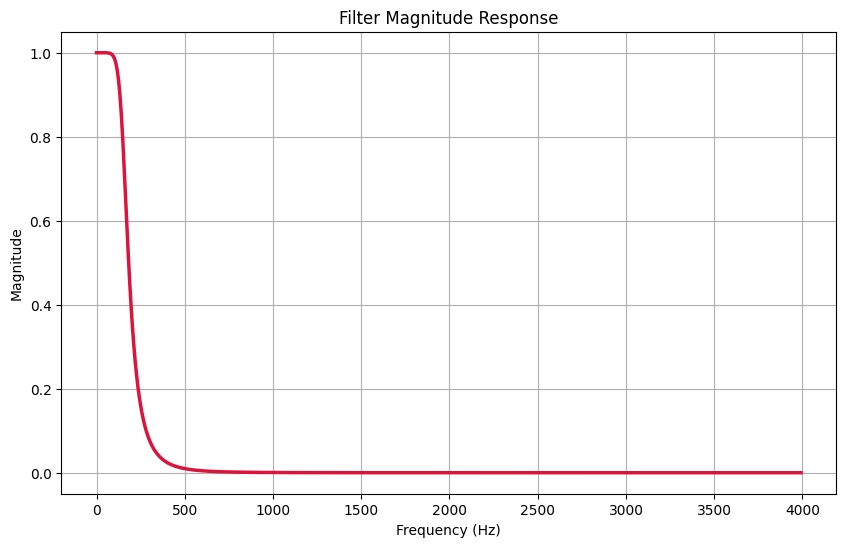

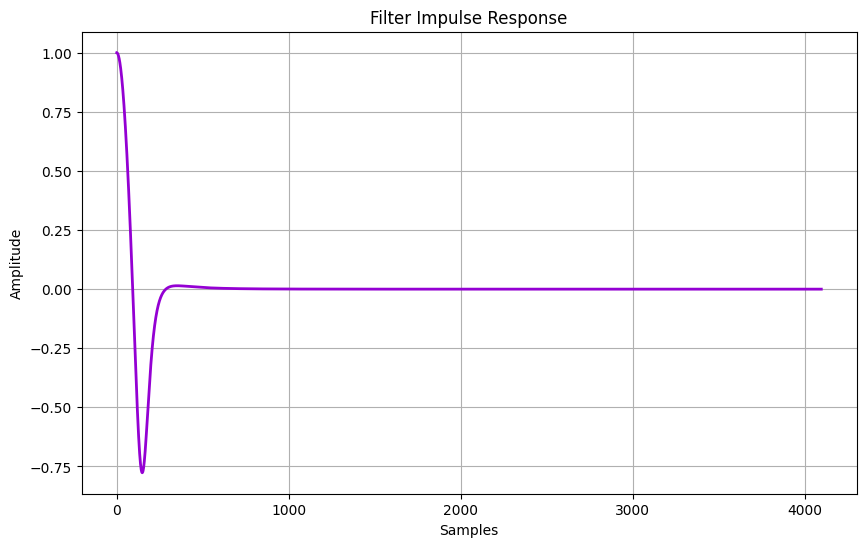

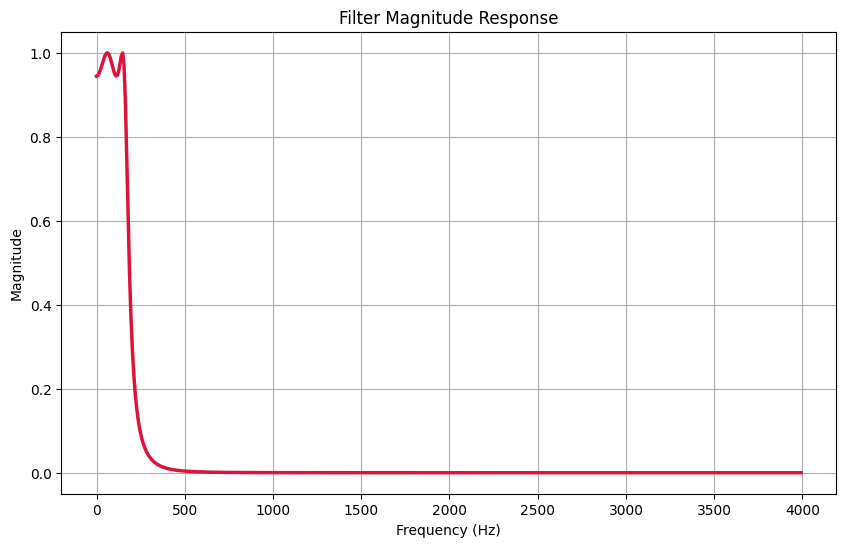

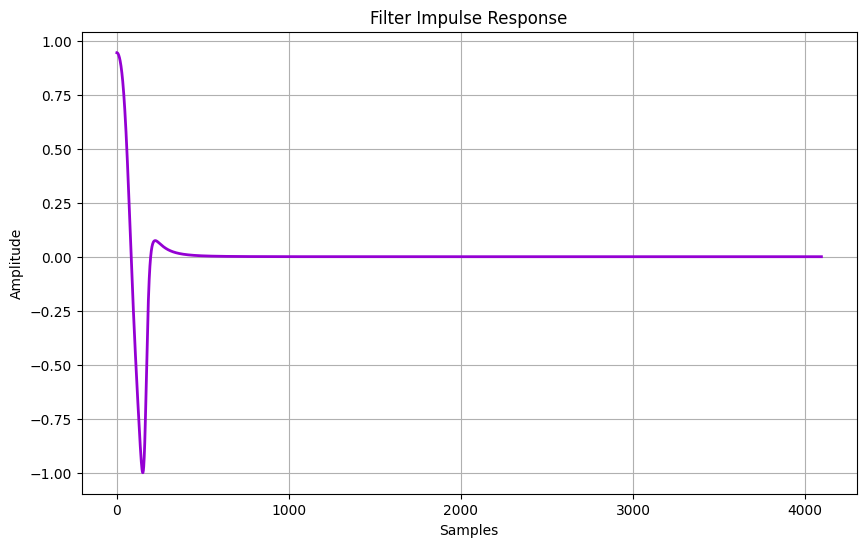

Filter coefficients saved at: filter_coefficients.txt


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, bilinear, freqz, cheby1

def design_butterworth_filter(filter_order, cutoff_frequency, sampling_frequency):
    analog_b, analog_a = butter(filter_order, cutoff_frequency, analog=True, btype='low')
    digital_b, digital_a = bilinear(analog_b, analog_a, sampling_frequency)
    return digital_b, digital_a

def design_chebyshev_filter(filter_order, cutoff_frequency, sampling_frequency, ripple):
    analog_b, analog_a = cheby1(filter_order, ripple, cutoff_frequency, analog=True, btype='low')
    digital_b, digital_a = bilinear(analog_b, analog_a, sampling_frequency)
    return digital_b, digital_a

def plot_filter_response(digital_b, digital_a, sampling_frequency):
    frequency, magnitude_response = freqz(digital_b, digital_a, fs=sampling_frequency)

    plt.figure(figsize=(10, 6))
    plt.plot(frequency, np.abs(magnitude_response), color='crimson', linewidth=2.5)
    plt.title('Filter Magnitude Response')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Magnitude')
    plt.grid(True)
    plt.show()

    _, impulse_response = freqz(digital_b, digital_a, fs=sampling_frequency, worN=4096)

    plt.figure(figsize=(10, 6))
    plt.plot(np.real(impulse_response), color='darkviolet', linewidth=2)
    plt.title('Filter Impulse Response')
    plt.xlabel('Samples')
    plt.ylabel('Amplitude')
    plt.grid(True)
    plt.show()

filter_order = 4
cutoff_frequency = 1000
sampling_frequency = 8000
ripple = 0.5

digital_b, digital_a = design_butterworth_filter(filter_order, cutoff_frequency, sampling_frequency)
plot_filter_response(digital_b, digital_a, sampling_frequency)

digital_b, digital_a = design_chebyshev_filter(filter_order, cutoff_frequency, sampling_frequency, ripple)
plot_filter_response(digital_b, digital_a, sampling_frequency)

filter_path = 'filter_coefficients.txt'
np.savetxt(filter_path, np.vstack((digital_b, digital_a)), delimiter=',')
print(f"Filter coefficients saved at: {filter_path}")

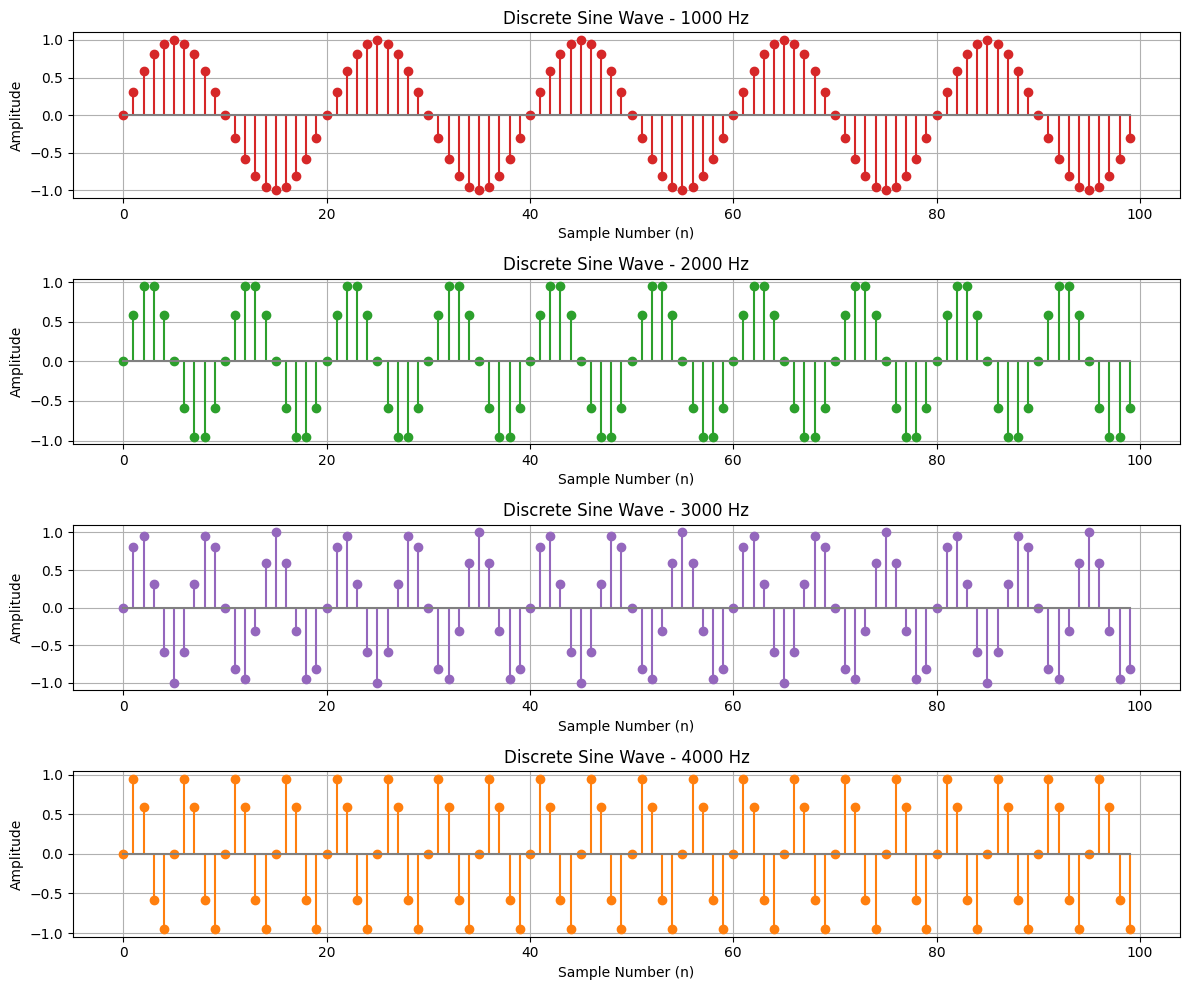

In [3]:
import numpy as np
import matplotlib.pyplot as plt

Fs = 20000
N = 100
n = np.arange(N)
frequencies = [1000, 2000, 3000, 4000]
colors = ['tab:red', 'tab:green', 'tab:purple', 'tab:orange']

plt.figure(figsize=(12, 10))
for i, f in enumerate(frequencies):
    x = np.sin(2 * np.pi * f * n / Fs)
    plt.subplot(4, 1, i + 1)
    plt.stem(n, x, linefmt=colors[i], markerfmt='o', basefmt='gray')
    plt.title(f"Discrete Sine Wave - {f} Hz")
    plt.xlabel("Sample Number (n)")
    plt.ylabel("Amplitude")
    plt.grid(True)

plt.tight_layout()
plt.show()

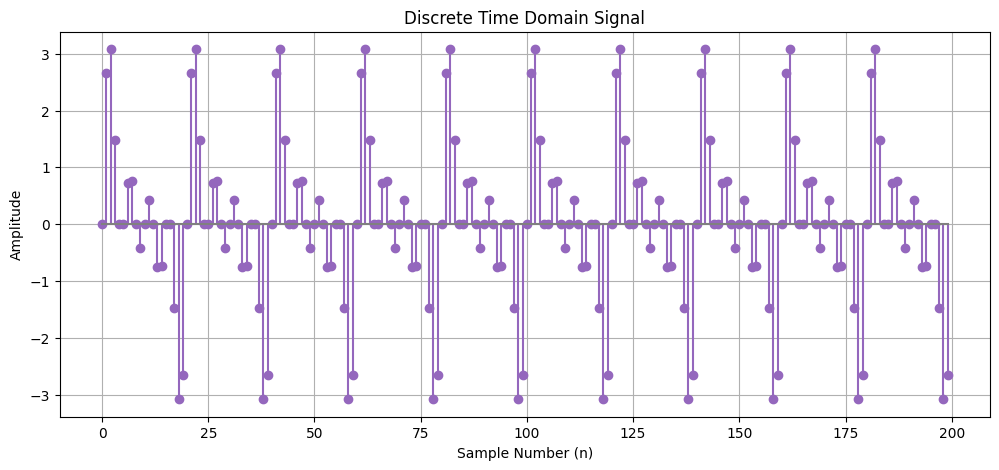

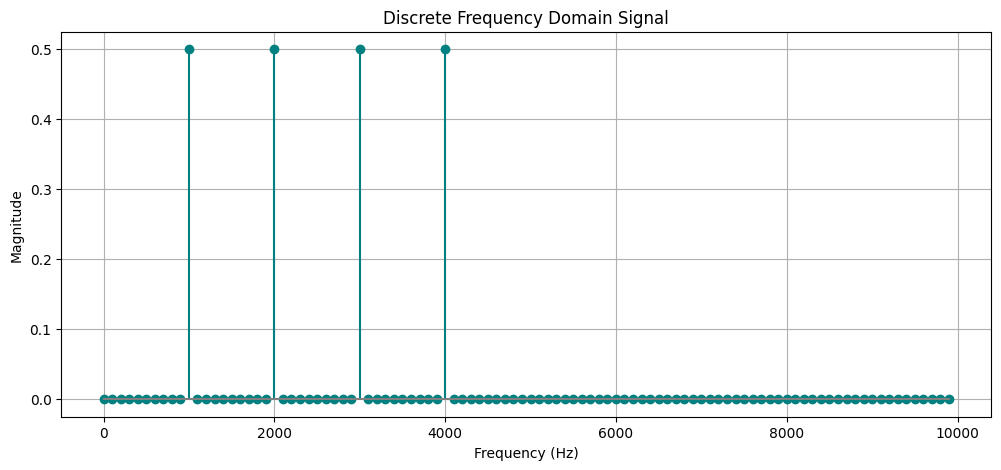

In [4]:
import numpy as np
import matplotlib.pyplot as plt

Fs = 20000
N = 200
n = np.arange(N)

x1 = np.sin(2 * np.pi * 1000 * n / Fs)
x2 = np.sin(2 * np.pi * 2000 * n / Fs)
x3 = np.sin(2 * np.pi * 3000 * n / Fs)
x4 = np.sin(2 * np.pi * 4000 * n / Fs)
x = x1 + x2 + x3 + x4

# Time domain plot
plt.figure(figsize=(12, 5))
plt.stem(n, x, linefmt='tab:purple', markerfmt='o', basefmt='gray')
plt.title("Discrete Time Domain Signal")
plt.xlabel("Sample Number (n)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

X = np.fft.fft(x)
freq = np.fft.fftfreq(N, 1 / Fs)
positive = freq >= 0

# Frequency domain plot
plt.figure(figsize=(12, 5))
plt.stem(freq[positive], np.abs(X[positive]) / N, linefmt='teal', markerfmt='o', basefmt='gray')
plt.title("Discrete Frequency Domain Signal")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.grid(True)
plt.show()

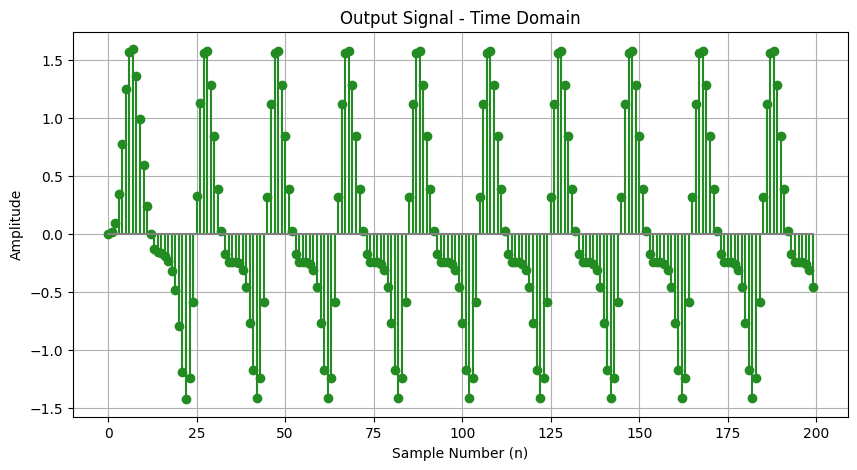

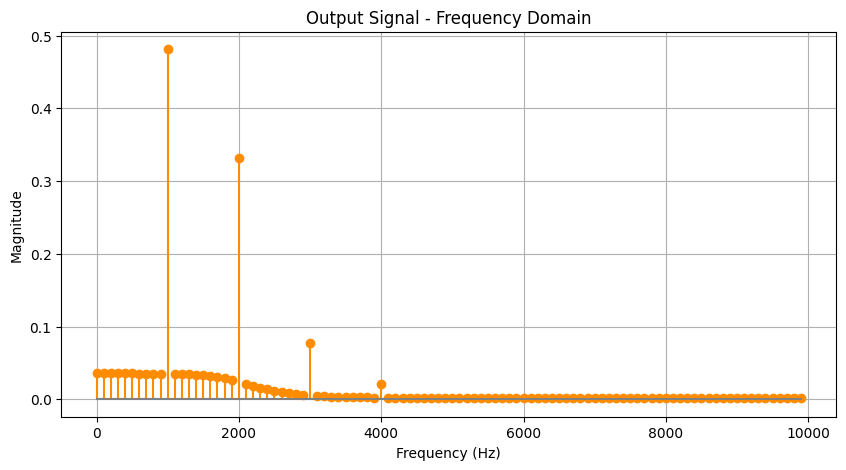

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, lfilter

Fs = 20000
N = 200
n = np.arange(N)

x1 = np.sin(2 * np.pi * 1000 * n / Fs)
x2 = np.sin(2 * np.pi * 2000 * n / Fs)
x3 = np.sin(2 * np.pi * 3000 * n / Fs)
x4 = np.sin(2 * np.pi * 4000 * n / Fs)
x = x1 + x2 + x3 + x4

fc = 2000
order = 4

b, a = butter(order, fc / (Fs / 2), btype='low')
y = lfilter(b, a, x)
Y = np.fft.fft(y)
freq = np.fft.fftfreq(N, 1 / Fs)
positive = freq >= 0

plt.figure(figsize=(10, 5))
plt.stem(n, y, linefmt='forestgreen', markerfmt='o', basefmt='gray')
plt.title("Output Signal - Time Domain")
plt.xlabel("Sample Number (n)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.stem(freq[positive], np.abs(Y[positive]) / N, linefmt='darkorange', markerfmt='o', basefmt='gray')
plt.title("Output Signal - Frequency Domain")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.grid(True)
plt.show()

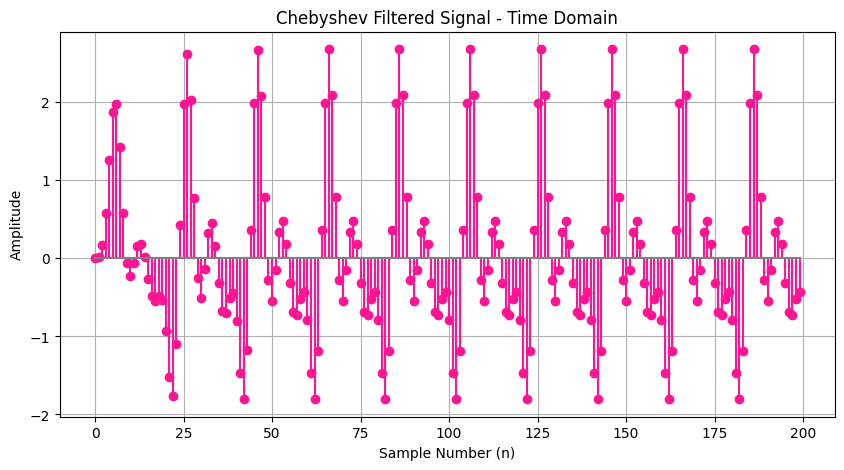

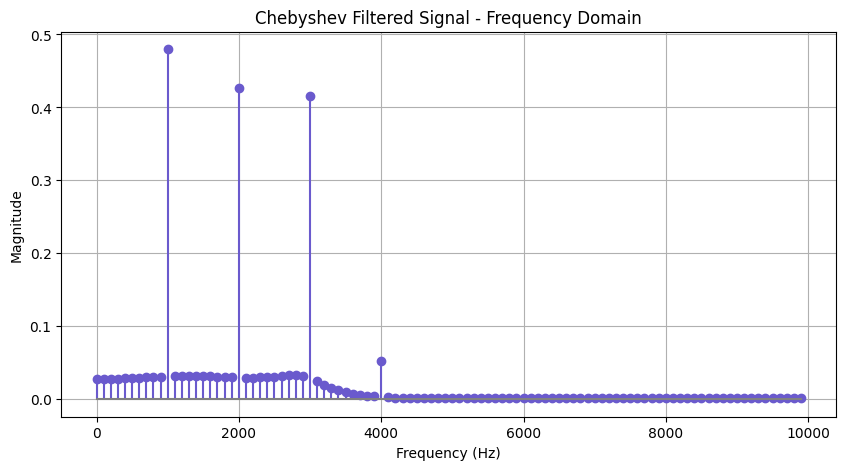

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import cheby1, lfilter
Fs = 20000
N = 200
n = np.arange(N)
f1 = 1000
f2 = 2000
f3 = 3000
f4 = 4000

x1 = np.sin(2 * np.pi * f1 * n / Fs)
x2 = np.sin(2 * np.pi * f2 * n / Fs)
x3 = np.sin(2 * np.pi * f3 * n / Fs)
x4 = np.sin(2 * np.pi * f4 * n / Fs)
x = x1 + x2 + x3 + x4

fc = 3000
order = 4
ripple = 1

b, a = cheby1(order, ripple, fc / (Fs / 2), btype='low')
y = lfilter(b, a, x)
Y = np.fft.fft(y)
freq = np.fft.fftfreq(N, 1 / Fs)
positive = freq >= 0

# Time domain output
plt.figure(figsize=(10, 5))
plt.stem(n, y, linefmt='deeppink', markerfmt='o', basefmt='gray')
plt.title("Chebyshev Filtered Signal - Time Domain")
plt.xlabel("Sample Number (n)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

# Frequency domain output
plt.figure(figsize=(10, 5))
plt.stem(freq[positive], np.abs(Y[positive]) / N, linefmt='slateblue', markerfmt='o', basefmt='gray')
plt.title("Chebyshev Filtered Signal - Frequency Domain")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.grid(True)
plt.show()